In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("AB_NYC_2019.csv")
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
def remove_invalid_listings(data):
    """Return a copy without duplicate listings or invalid numeric values."""
    cleaned = data.copy()
    cleaned = cleaned.drop_duplicates(subset="id")
    cleaned = cleaned.loc[cleaned["price"].gt(0)]
    cleaned = cleaned.loc[cleaned["minimum_nights"].gt(0)]
    cleaned = cleaned.loc[cleaned["availability_365"].between(0, 365)]
    return cleaned.reset_index(drop=True)


def clean_review_data(data):
    """Standardize review dates and fill missing monthly reviews with zero."""
    cleaned = data.copy()
    cleaned["last_review"] = pd.to_datetime(cleaned["last_review"], errors="coerce")
    no_reviews = cleaned["number_of_reviews"].eq(0)
    cleaned.loc[no_reviews, "reviews_per_month"] = 0.0
    return cleaned


cleaned_df = clean_review_data(remove_invalid_listings(df))
cleaned_df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
def exploratory_analysis(data):
    """Return summary statistics, borough metrics, and numeric correlations."""
    numeric_columns = data.select_dtypes(include="number")
    summary_statistics = numeric_columns.describe().T
    grouped_view = (
        data.groupby("neighbourhood_group")
        .agg(
            listings=("id", "count"),
            average_price=("price", "mean"),
            median_price=("price", "median"),
            average_reviews=("number_of_reviews", "mean"),
            average_availability=("availability_365", "mean"),
        )
        .sort_values("average_price", ascending=False)
    )
    correlations = numeric_columns.corr()
    return {
        "summary_statistics": summary_statistics,
        "grouped_view": grouped_view,
        "correlations": correlations,
    }


eda_results = exploratory_analysis(cleaned_df)
display(eda_results["summary_statistics"])
display(eda_results["grouped_view"])
display(eda_results["correlations"])

,count,mean,std,min,25%,50%,75%,max
id,48884.0,1.901679e+07,1.098432e+07,2539.00000,9.470548e+06,1.967574e+07,2.915297e+07,3.648724e+07
host_id,48884.0,6.762203e+07,7.861666e+07,2438.00000,7.817310e+06,3.079257e+07,1.074344e+08,2.743213e+08
latitude,48884.0,4.072895e+01,5.453177e-02,40.49979,4.069010e+01,4.072308e+01,4.076312e+01,4.091306e+01
longitude,48884.0,-7.395218e+01,4.615874e-02,-74.24442,-7.398308e+01,-7.395569e+01,-7.393629e+01,-7.371299e+01
price,48884.0,1.527551e+02,2.401703e+02,10.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48884.0,7.029887e+00,2.051222e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48884.0,2.327199e+01,4.455133e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,48884.0,1.090800e+00,1.597213e+00,0.00000,4.000000e-02,3.700000e-01,1.580000e+00,5.850000e+01
calculated_host_listings_count,48884.0,7.144628e+00,3.295619e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48884.0,1.127795e+02,1.316273e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


,listings,average_price,median_price,average_reviews,average_availability
neighbourhood_group,,,,,
Manhattan,21660,196.884903,150.0,20.986565,111.984580
Brooklyn,20095,124.438915,90.0,24.197661,100.217318
Staten Island,373,114.812332,75.0,30.941019,199.678284
Queens,5666,99.517649,75.0,27.700318,144.451818
Bronx,1090,87.577064,65.0,25.977982,165.794495


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
id,1.000000,0.588316,-0.003115,0.090895,0.010639,-0.013229,-0.319800,0.180240,0.133275,0.085468
host_id,0.588316,1.000000,0.020199,0.127022,0.015294,-0.017391,-0.140181,0.209752,0.154949,0.203434
latitude,-0.003115,0.020199,1.000000,0.084830,0.033899,0.024893,-0.015357,-0.018719,0.019518,-0.010942
longitude,0.090895,0.127022,0.084830,1.000000,-0.149954,-0.062772,0.059015,0.138435,-0.114715,0.082669
price,0.010639,0.015294,0.033899,-0.149954,1.000000,0.042805,-0.047926,-0.050531,0.057462,0.081847
minimum_nights,-0.013229,-0.017391,0.024893,-0.062772,0.042805,1.000000,-0.080080,-0.124870,0.127962,0.144275
number_of_reviews,-0.319800,-0.140181,-0.015357,0.059015,-0.047926,-0.080080,1.000000,0.589311,-0.072385,0.171975
reviews_per_month,0.180240,0.209752,-0.018719,0.138435,-0.050531,-0.124870,0.589311,1.000000,-0.047322,0.163664
calculated_host_listings_count,0.133275,0.154949,0.019518,-0.114715,0.057462,0.127962,-0.072385,-0.047322,1.000000,0.225712
availability_365,0.085468,0.203434,-0.010942,0.082669,0.081847,0.144275,0.171975,0.163664,0.225712,1.000000


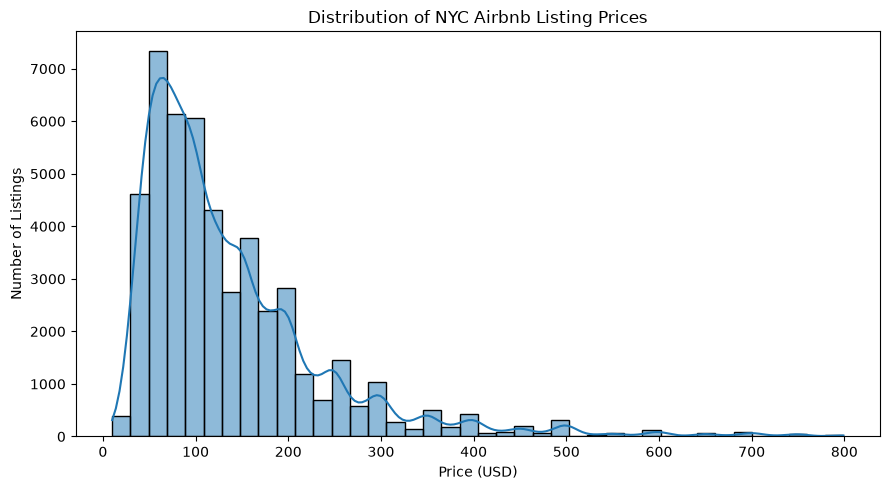

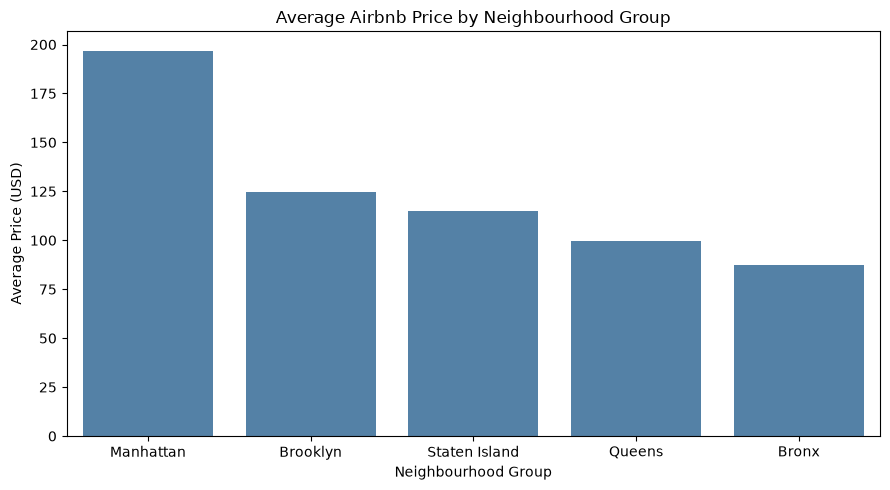

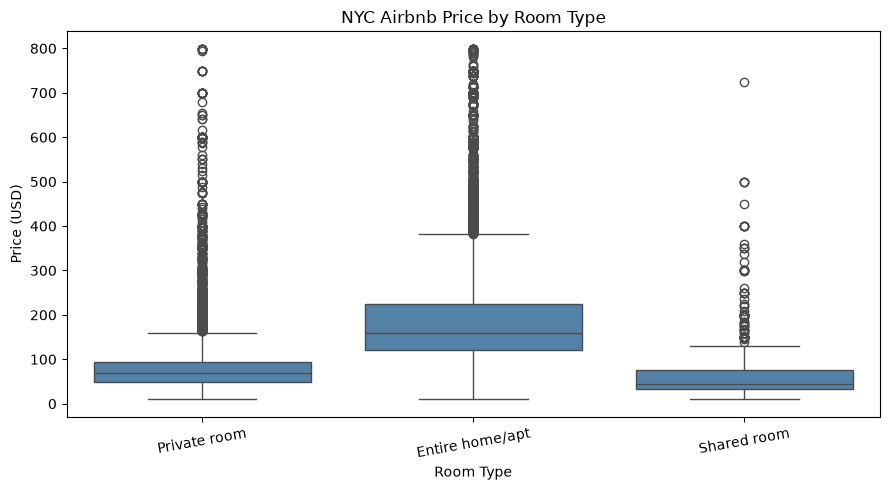

In [7]:
# Visualization 1: Distribution of listing prices (limited to 99th percentile)
price_limit = cleaned_df["price"].quantile(0.99)
plt.figure(figsize=(9, 5))
sns.histplot(cleaned_df.loc[cleaned_df["price"] <= price_limit, "price"], bins=40, kde=True)
plt.title("Distribution of NYC Airbnb Listing Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

# Visualization 2: Average price by neighbourhood group
average_prices = eda_results["grouped_view"]["average_price"]
plt.figure(figsize=(9, 5))
sns.barplot(x=average_prices.index, y=average_prices.values, color="steelblue")
plt.title("Average Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Price (USD)")
plt.tight_layout()
plt.show()

# Visualization 3: Price patterns by room type
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=cleaned_df.loc[cleaned_df["price"] <= price_limit],
    x="room_type",
    y="price",
    color="steelblue",
)
plt.title("NYC Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price (USD)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## Task 8 — Summary and Interpretation

The dataset contains information about 2019 Airbnb listings in New York City, including their location, room type, price, availability, and review activity. After cleaning invalid prices and minimum-night values and standardizing review fields, the analysis showed that Manhattan has the highest average nightly price, while the Bronx has the lowest. Brooklyn and Manhattan contain most of the listings in the dataset.

The distributions and grouped results also show that entire homes and apartments generally cost more than private or shared rooms. Staten Island has relatively few listings but the highest average availability, while Manhattan has lower availability on average despite having the highest prices. Review counts are highly variable, and the correlation analysis does not show a strong linear relationship between price and review activity.

The analysis assumes that each `id` represents one unique listing and that positive prices and minimum-night values are valid. Missing monthly review values are treated as zero only when a listing has no reviews, while missing review dates remain missing. The dataset is a snapshot from 2019, so its prices, availability, and listing status may not represent current market conditions. It is also surprising and somewhat unclear that a small number of listings have extremely large prices or minimum-night requirements, and the dataset does not explain whether those values are errors, special listings, or intentional settings.